# Phase 2.1 — คู่คำที่สับสน: THSL Example Dictionary

**เริ่มจาก ชอบ–ข้าว** แล้วตรวจ ฉัน–คุณ, ฉัน–แฟน, ลืม–ญาติ, ช่วย–ขนมปัง

เป้าหมาย: ตรวจว่าระบบสับสนเพราะรูปมือ ทิศมือ การเคลื่อน ตำแหน่ง หรือเพราะช่วงคำ/เฉลยยังไม่ตรง ก่อนเตรียมข้อมูลฝึกเพิ่มเติม

นี่คือ Notebook ใหม่สำหรับงานคู่คำโดยเฉพาะ ใช้ `.py` และข้อมูลจริงทั้งหมด ไม่เปลี่ยน Notebook Hybrid เดิม ไม่ฝึกโมเดลจาก pseudo-label โดยอัตโนมัติ

**ขอบเขตหลักฐาน:** ทั้งห้าคู่พบคู่ละ 1 ครั้งจาก text edit alignment ของคลิป Boom จึงเรียกว่า “คู่ต้องตรวจ” ไม่ใช่ยืนยันว่าผิดบ่อย ข้อมูล THSL ฝั่งบางคำมีคนเดียว ยังไม่พอทดสอบกับคนใหม่

## 1. Setup

การอ่าน parquet/สกัดคุณลักษณะใช้ venv-sign2say; OpenCV ใช้ subprocess ที่แยกไว้แล้วเพื่อหลีกเลี่ยง NumPy ABI ของ Anaconda โค้ดสร้างรูปใช้ kernel Notebook

In [1]:
from pathlib import Path
import sys, importlib
ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'modules/pipeline.py').exists()),None)
if ROOT is None: raise FileNotFoundError('เปิด Notebook ภายใน DSI490-Sign2Say')
HERE=ROOT/'Boom/phase2.1/04_confusing_pairs'
sys.path.insert(0,str(HERE));sys.path.insert(0,str(HERE.parent/'02_hybrid_score'))
import pair_analysis as pa
import experiment_analysis as ex
importlib.reload(pa);importlib.reload(ex)
ex.setup()
pa.show(ex.environment(),'**ตรวจ environment:** inference/extraction ใช้ project Python; Notebook kernel ใช้แสดงตารางและกราฟ')

,component,value
0,python,"3.11.8 (main, Apr 19 2025, 22:30:49) [Clang 14.0.3 (clang-1403.0.22.14.1)]"
1,executable,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/venv-sign2say/bin/python
2,platform,macOS-26.2-arm64-arm-64bit
3,torch,2.14.1
4,onnxruntime,1.23.2
5,providers,"['CoreMLExecutionProvider', 'AzureExecutionProvider', 'CPUExecutionProvider']"
6,mediapipe,1.1.0
7,project_imports,OK
8,notebook_kernel,/Users/thawaphorn/anaconda3/bin/python


**ตรวจ environment:** inference/extraction ใช้ project Python; Notebook kernel ใช้แสดงตารางและกราฟ

## 2. สร้าง dict ตัวอย่างจริงและตรวจความพร้อม

อ่าน shards/clips.parquet เฉพาะ th_sl + mp แล้ว deduplicate clip_id ไม่รวม RTMW เป็นคนหรือคลิปใหม่ ตรวจ raw landmarks, standard landmarks และวิดีโอตาม manifest

ไม่มีการย้ายคลิป val/test มาเป็น train เพื่อเพิ่มจำนวน หากต้อง split ใหม่ต้องออกแบบและบันทึกก่อนเริ่มทดลอง

In [2]:
pa.run_prepare()
pairs=pa.table('pairs')
pa.show(pairs,'**อ่านตาราง:** a=คำอ้างอิงที่เสนอ, b=คำตอบของ AI; ready_for_review แปลว่ามี raw hands ทั้งสองคำ ไม่ได้แปลว่าพร้อมเทรน. เกณฑ์ train ≥3 คน/คำเป็นเพียงเกณฑ์คัดกรองเบื้องต้น')
clips=pa.table('thsl_clips')
pa.show(clips,'**แหล่งข้อมูล:** source_file คือพาธใน manifest; local_video ว่างแปลว่ายังหาไฟล์ RGB ไม่เจอที่พาธที่ตรวจ raw_exists=True ยังเปิดโครงมือจริงได้')

Prepared 12 real THSL clips across 9 concepts


,pair_id,reference,prediction,observed_errors,a_clips,a_signers,a_train_clips,a_train_signers,a_raw_available,a_videos_available,b_clips,b_signers,b_train_clips,b_train_signers,b_raw_available,b_videos_available,ready_for_review,multi_signer_training_ready
0,pair01,ชอบ,ข้าว,1,2,2,2,2,2,0,1,1,1,1,1,0,True,False
1,pair02,ฉัน,คุณ,1,1,1,1,1,1,0,1,1,1,1,1,0,True,False
2,pair03,ฉัน,แฟน,1,1,1,1,1,1,0,2,2,2,2,2,0,True,False
3,pair04,ลืม,ญาติ,1,1,1,1,1,1,0,2,2,2,2,2,0,True,False
4,pair05,ช่วย,ขนมปัง,1,1,1,1,1,1,0,1,1,1,1,1,0,True,False


**อ่านตาราง:** a=คำอ้างอิงที่เสนอ, b=คำตอบของ AI; ready_for_review แปลว่ามี raw hands ทั้งสองคำ ไม่ได้แปลว่าพร้อมเทรน. เกณฑ์ train ≥3 คน/คำเป็นเพียงเกณฑ์คัดกรองเบื้องต้น

,clip_id,word,signer,role,raw_path,raw_exists,standard_path,standard_exists,source_file,local_video,n_frames,duration_s,left_observed,right_observed
0,thsl:th_sl_00164,ฉัน,S_thsl_04,train,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp_raw/th_sl/th_sl_0...,True,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp/th_sl/th_sl_00164...,True,raw_data/word_level/th_sl_dictionary/videos/th_sl/th_sl_00164.mp4,NaN,83,3.280,0.000,0.265
1,thsl:th_sl_00172,คุณ,S_thsl_04,train,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp_raw/th_sl/th_sl_0...,True,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp/th_sl/th_sl_00172...,True,raw_data/word_level/th_sl_dictionary/videos/th_sl/th_sl_00172.mp4,NaN,87,3.440,0.000,0.299
2,thsl:th_sl_00204,แฟน,S_thsl_04,train,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp_raw/th_sl/th_sl_0...,True,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp/th_sl/th_sl_00204...,True,raw_data/word_level/th_sl_dictionary/videos/th_sl/th_sl_00204.mp4,NaN,91,3.600,0.000,0.319
3,thsl:th_sl_00213,ญาติ,S_thsl_04,train,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp_raw/th_sl/th_sl_0...,True,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp/th_sl/th_sl_00213...,True,raw_data/word_level/th_sl_dictionary/videos/th_sl/th_sl_00213.mp4,NaN,99,3.920,0.000,0.303
4,thsl:th_sl_00449,ขนมปัง,S_thsl_05,train,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp_raw/th_sl/th_sl_0...,True,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp/th_sl/th_sl_00449...,True,raw_data/word_level/th_sl_dictionary/videos/th_sl/th_sl_00449.mp4,NaN,118,4.680,0.356,0.280
5,thsl:th_sl_00451,ข้าว,S_thsl_05,train,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp_raw/th_sl/th_sl_0...,True,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp/th_sl/th_sl_00451...,True,raw_data/word_level/th_sl_dictionary/videos/th_sl/th_sl_00451.mp4,NaN,109,4.320,0.000,0.376
6,thsl:th_sl_00827,ชอบ,S_thsl_05,train,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp_raw/th_sl/th_sl_0...,True,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp/th_sl/th_sl_00827...,True,raw_data/word_level/th_sl_dictionary/videos/th_sl/th_sl_00827.mp4,NaN,94,3.720,0.000,0.362
7,thsl:th_sl_00842,ลืม,S_thsl_05,train,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp_raw/th_sl/th_sl_0...,True,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp/th_sl/th_sl_00842...,True,raw_data/word_level/th_sl_dictionary/videos/th_sl/th_sl_00842.mp4,NaN,88,3.480,0.000,0.386
8,thsl:th_sl_01604,ชอบ,S_thsl_00,train,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp_raw/th_sl/th_sl_0...,True,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp/th_sl/th_sl_01604...,True,raw_data/word_level/th_sl_dictionary/videos/th_sl/th_sl_01604.mp4,NaN,50,1.960,0.000,0.540
9,thsl:th_sl_02122,ช่วย,S_thsl_00,train,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp_raw/th_sl/th_sl_0...,True,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/cloud_s3/data_prep/pose_mp/th_sl/th_sl_02122...,True,raw_data/word_level/th_sl_dictionary/videos/th_sl/th_sl_02122.mp4,NaN,48,1.880,0.583,0.625


**แหล่งข้อมูล:** source_file คือพาธใน manifest; local_video ว่างแปลว่ายังหาไฟล์ RGB ไม่เจอที่พาธที่ตรวจ raw_exists=True ยังเปิดโครงมือจริงได้

## 3. หลักฐานว่าคู่ใดเกิดที่คลิปและช่วงไหน

ตารางนี้อ้างอิงผล AI-only เท่านั้น ไม่รวม Hybrid ซ้ำเป็นอีกเหตุการณ์ แต่ละแถวต้องตรวจทั้งวิดีโอและจุดเริ่ม–จบก่อนยืนยัน true_word

In [3]:
pa.show(pa.table('boom_evidence'),'**ข้อจำกัด:** ground_truth คอลัมน์เก่ามาจากการ align ข้อความกับผลทำนาย จึงยังไม่ใช่ human segment label. จำนวนครั้งต้องอ่านร่วมกับข้อมูลนี้')

,pair_id,video,mode,segment,t0,t1,word,status,p_correct,ground_truth,correctness,top1_covered,top5_covered,left_observed,right_observed,observed_attributes
0,pair01,ฉันแอบชอบคุณ.MOV,ai_only,6,10.080,11.200,ข้าว,unknown,0.075,ชอบ,✗,False,False,NaN,NaN,{}
1,pair02,ฉันยังลืมคุณไม่ได้.MOV,ai_only,2,3.840,5.280,คุณ,unknown,0.058,ฉัน,✗,False,False,NaN,NaN,{}
2,pair03,ฉันแอบชอบคุณ.MOV,ai_only,4,7.360,8.320,แฟน,unknown,0.206,ฉัน,✗,False,False,NaN,NaN,{}
3,pair04,ฉันยังลืมคุณไม่ได้.MOV,ai_only,4,6.560,8.480,ญาติ,uncertain,0.272,ลืม,✗,False,False,NaN,NaN,{}
4,pair05,มีอะไรให้ฉันช่วยไหม.MOV,ai_only,7,11.840,12.640,ขนมปัง,unknown,0.085,ช่วย,✗,False,False,NaN,NaN,{}


**ข้อจำกัด:** ground_truth คอลัมน์เก่ามาจากการ align ข้อความกับผลทำนาย จึงยังไม่ใช่ human segment label. จำนวนครั้งต้องอ่านร่วมกับข้อมูลนี้

### แก้ไขตามผู้ใช้ตรวจภาพจริง — คู่ ชอบ–ข้าว

| ภาพ | เวลาโดยประมาณ | ผู้ใช้ยืนยัน |
|---|---|---|
| 1 | 10.19s | ฉัน |
| 2 | 10.42s | ชอบ |
| 3 | 10.64s | ชอบ |
| 4 | 10.86s | ชอบ |
| 5 | 11.09s | ไม่ได้ทำท่า / พัก |

**ข้อค้นพบ:** ช่วงเดิม 10.08–11.20s ปนสองคำและช่วงพัก จึงนำทั้งช่วงไปเป็น hard negative ชอบ–ข้าวไม่ได้ ต้องตรวจขอบเขตของท่าชอบแล้ว rerun recognition บนช่วงที่สะอาดก่อน. การยืนยันนี้เป็นป้ายของภาพที่แสดง ไม่ได้อนุมานว่าคำเริ่ม/จบตรง timestamp ของภาพเหล่านี้


## 4. เปิดคู่แรก: ชอบ–ข้าว

เลือก PAIR_ID เปลี่ยนเป็น pair02–pair05 ได้ แต่เริ่มตรวจทีละคู่เพื่อบันทึกว่าท่าที่เห็นจริงคืออะไร

ขั้นตรวจ: ดูคลิปทั้งประโยค → ดูภาพ 5 จุดในช่วงที่ระบบตัด → ตรวจ Top-5 → ยืนยันว่าช่วงนั้นเป็นคำอ้างอิงจริงหรือไม่ ถ้าไม่ใช่ให้แก้ใน manual_review.json

In [ ]:
PAIR_ID='pair01'
pa.boom_examples(PAIR_ID)

## 5. เทียบคลิปต้นแบบ THSL ผ่าน raw hand landmarks

แสดงทุกคลิปที่มีของสองคำ พร้อม signer และ role เลือกต้น/กลาง/ท้ายจากเฟรมที่ตรวจพบมือ ภาพนี้เป็นโครงมือจากข้อมูลจริง ไม่ใช่ภาพ RGB ที่สร้างขึ้น

raw มี x,y,z แต่ภาพฉาย 2D ไม่ยืนยันว่าแบ/กำหรือหันเข้ากล้องถูกทุกเฟรม ข้อมูลดิบยังเก็บไว้ครบสำหรับตรวจต่อ ไม่ถือ standard schema ที่เติมจุดแล้วว่าเป็นมือที่ detector เห็นจริง

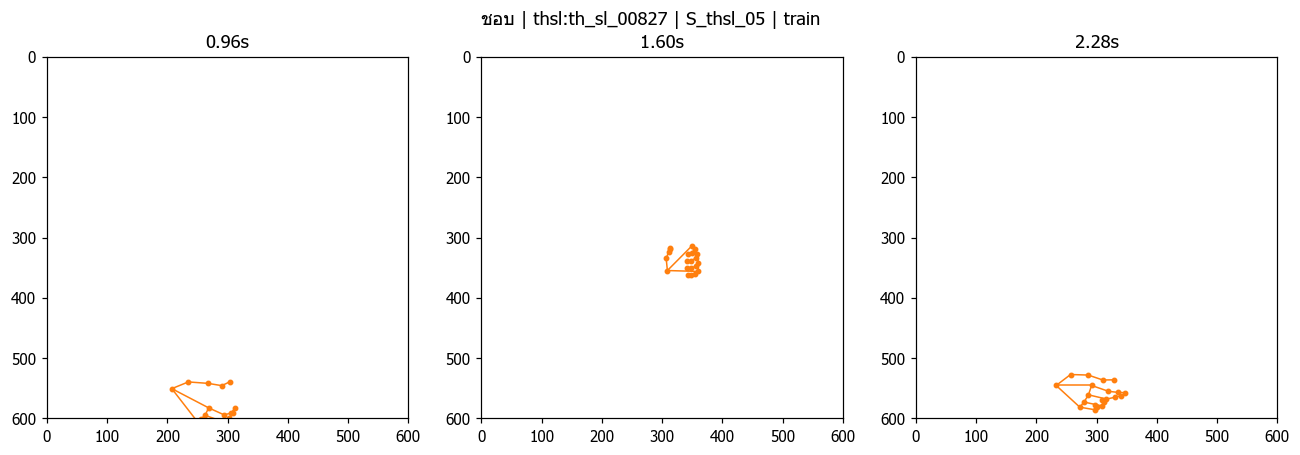

**ภาพโครงมือจริง:** เลือกต้น/กลาง/ท้ายจากเฟรมที่เห็นมือ ไม่ใช่ภาพ RGB และไม่ใช่การยืนยันช่วงท่าหลัก; แกนถูกปรับตามสัดส่วนภาพจริง มือที่บังกันยังทำให้ landmark ผิดได้

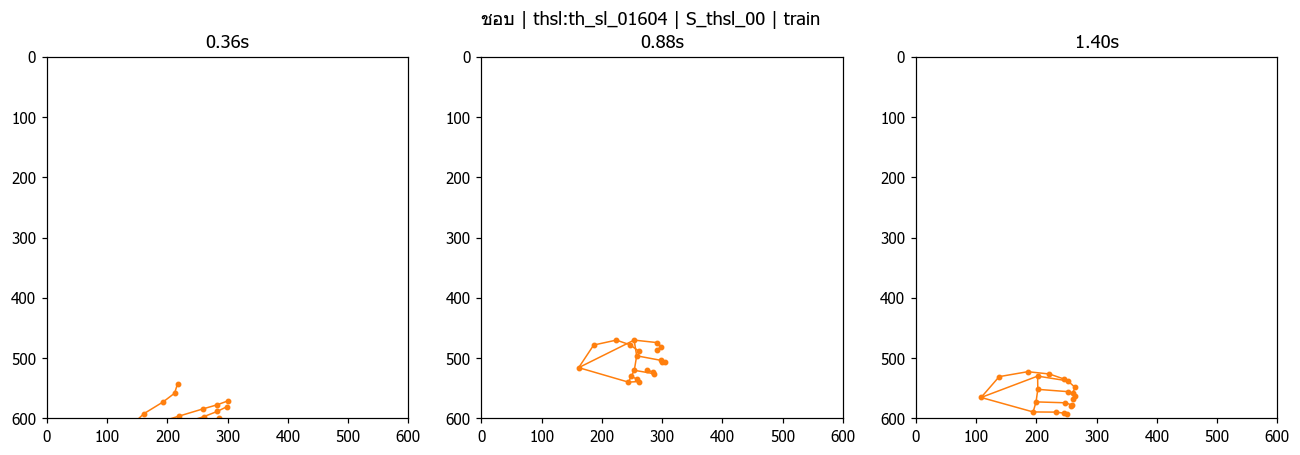

**ภาพโครงมือจริง:** เลือกต้น/กลาง/ท้ายจากเฟรมที่เห็นมือ ไม่ใช่ภาพ RGB และไม่ใช่การยืนยันช่วงท่าหลัก; แกนถูกปรับตามสัดส่วนภาพจริง มือที่บังกันยังทำให้ landmark ผิดได้

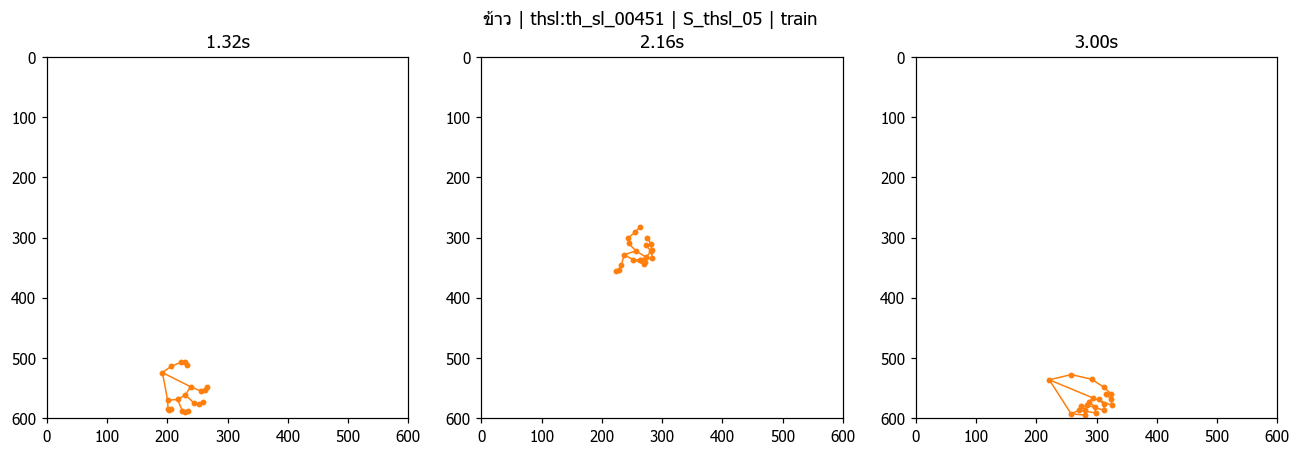

**ภาพโครงมือจริง:** เลือกต้น/กลาง/ท้ายจากเฟรมที่เห็นมือ ไม่ใช่ภาพ RGB และไม่ใช่การยืนยันช่วงท่าหลัก; แกนถูกปรับตามสัดส่วนภาพจริง มือที่บังกันยังทำให้ landmark ผิดได้

In [5]:
pa.pair_examples(PAIR_ID)

บันทึกเฉลยตามพี่ใน Notebook แล้วครับ:
เวลา	ท่าที่ถูกต้อง
10.19s	ฉัน
10.42s, 10.64s, 10.86s	ชอบ
11.09s	ไม่ได้ทำท่า / พัก

## 6. ลองสกัด attribute จากตัวอย่างจริง

ใช้ HandStateTracker ตัวเดียวกับการทดลองก่อนหน้า: มุมข้อนิ้ว + reach ratio + temporal consensus มี unknown เมื่อข้อมูลไม่พอ นี่เป็นผลจากกฎที่ต้องตรวจ ไม่ใช่ label ฝึกที่รับรองแล้ว

ทิศฝ่ามือ/ชี้เข้ากล้องยังไม่มีโมเดลที่ validate แล้ว ห้ามสรุปจากกราฟนี้ว่ารู้จำ orientation ได้

,word,side,shape,frames,fraction
0,ขนมปัง,left,four_extended,24,0.203
1,ขนมปัง,left,open,14,0.119
2,ขนมปัง,left,unknown,80,0.678
3,ขนมปัง,right,fist,3,0.025
4,ขนมปัง,right,open,2,0.017
5,ขนมปัง,right,unknown,113,0.958
6,ข้าว,left,unknown,109,1.000
7,ข้าว,right,unknown,109,1.000
8,คุณ,left,unknown,87,1.000
9,คุณ,right,index_point,12,0.138


**ผลประมาณ:** นับทุกเฟรมรวมช่วงพัก ไม่ใช่ handshape label ของคำทั้งคำ; unknown ไม่ใช่ folded และห้ามใช้จำนวนเฟรมแทนจำนวนตัวอย่างอิสระ

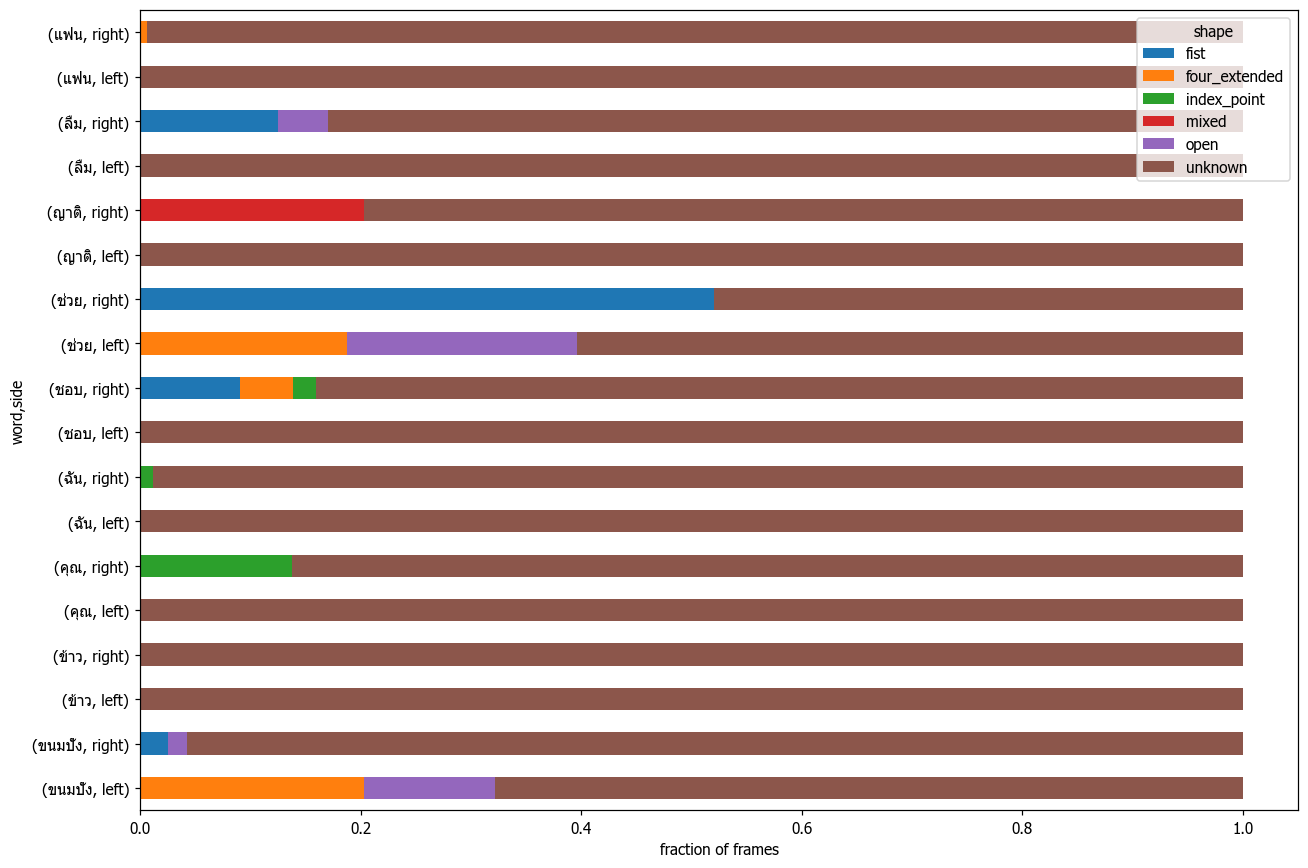

**อ่านกราฟ:** ความต่างที่เห็นเป็นสมมติฐานให้ตรวจต่อ อาจเกิดจาก detector/mุมกล้อง/ช่วงพัก ไม่ได้พิสูจน์ว่าคู่นี้ต่างกันที่รูปมือ

In [6]:
pa.attribute_summary()

## 7. Human review ที่ต้องทำก่อนฝึก

แก้ `manual_review.json` โดยไม่ต้องสร้าง Notebook เพิ่ม:

- `segments`: หลังดูวิดีโอ กำหนด true_word และ boundary_verified; ถ้าตัดผิดเขียน notes พร้อมเวลาที่ถูก
- `hand_attributes`: ใส่ intervals ตามเวลาจริง เช่น side, t0, t1, finger_states, palm_direction และ uncertainty; ช่องที่มองไม่ชัดเว้นไว้
- verified=true เฉพาะรายการที่ตรวจแล้ว ไม่คัดลอกชื่อคำไปเป็นรูปมือทั้งคลิป

การ rerun prepare จะไม่ทับ manual review ที่แก้แล้ว

In [ ]:
pa.show(pa.review_status(),'**รายการรอตรวจ:** ค่า False/null เป็นสถานะที่ยังไม่มีผู้ตรวจ ไม่ใช่ผลว่าโมเดลผิดทั้งหมด')

## 8. จุดตัดสินใจสำหรับการฝึก

| สิ่งที่พบหลังตรวจ | การทดลองที่เหมาะ |
|---|---|
| ขอบเขตช่วงผิด/อ้างอิงผิด | แก้ annotation ก่อน ยังไม่ใช้เป็น hard negative |
| คำจริงไม่อยู่ bank/vocabulary | ตรวจ mapping และคลิปที่มี ก่อนปรับ encoder |
| คู่ท่าต่างที่รูปมือและมีภาพพอ | เตรียม hand-crop + landmark labels |
| ต่างที่การเคลื่อนไหว | ใช้ลำดับเวลา ไม่เอาเฟรมเดี่ยวเป็นตัวแทนทั้งหมด |
| คนทำมีเพียงคนเดียว | เก็บเพิ่ม/ตรวจแหล่งอื่น ยังไม่อ้าง signer-independent accuracy |

การฝึกภายหลัง: baseline encoder เดิม → เพิ่มตัวอย่าง/contrastive hard negatives เฉพาะ train → เลือกค่าบน validation → ทดสอบคนใหม่ ชุด Boom นี้ถูกใช้ค้นปัญหาแล้ว จึงต้องมีชุดใหม่สำหรับยืนยันผลสุดท้าย

In [ ]:
pa.show(pa.readiness(),'**Gate:** False หมายถึงยังไม่พร้อมตามเกณฑ์ที่ประกาศ ไม่ใช้จำนวนเฟรมมากมาทดแทนจำนวนคนทำ')

## 9. สิ่งที่ได้จาก Notebook นี้

- pairs.csv: คู่ต้องตรวจและจำนวนข้อมูลจริงแยกคำ/คน/split
- thsl_clips.csv + thsl_example_dictionary.json: dict รายคำที่เชื่อมกลับคลิปและ raw pose
- boom_evidence.csv: จุดผิดที่ต้องตรวจในวิดีโอเรา
- estimated_finger_states.csv: ผลกฎรูปมือต่อเฟรม ไม่ใช่เฉลย
- manual_review.json: ป้ายที่คนตรวจ ไม่ถูกทับเมื่อ rerun
- provenance.json: hash แหล่งข้อมูลและวิธีนับ

**ยังไม่รายงานผล fine-tune:** Notebook นี้สร้างชุดหลักฐานเพื่อเลือกข้อมูลฝึกก่อน ไม่มีโมเดลจำลอง ไม่มีค่าความแม่นสมมติ

In [9]:
pa.show(__import__('pandas').DataFrame([{'file':p.name,'path':str(p)} for p in sorted(pa.OUT.iterdir()) if p.suffix in {'.csv','.json'}]),'**ไฟล์ส่งต่อ:** เก็บคู่กับ manual_review.json เพื่อแยกผลอัตโนมัติออกจากข้อมูลที่คนรับรอง')

,file,path
0,boom_evidence.csv,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/phase2.1/04_confusing_pairs/outputs/boo...
1,estimated_finger_states.csv,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/phase2.1/04_confusing_pairs/outputs/est...
2,pairs.csv,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/phase2.1/04_confusing_pairs/outputs/pai...
3,provenance.json,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/phase2.1/04_confusing_pairs/outputs/pro...
4,thsl_clips.csv,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/phase2.1/04_confusing_pairs/outputs/ths...
5,thsl_example_dictionary.json,/Users/thawaphorn/Pee4/Term1/DSI490/DSI490-Sign2Say/Boom/phase2.1/04_confusing_pairs/outputs/ths...


**ไฟล์ส่งต่อ:** เก็บคู่กับ manual_review.json เพื่อแยกผลอัตโนมัติออกจากข้อมูลที่คนรับรอง